# 06 - Estimer la gravité avec une régression logistique

Les notebooks précédents ont construit une table fiable, décrit les usagers et mesuré
plusieurs écarts de gravité. Nous examinons maintenant si des caractéristiques combinées
permettent de produire des probabilités plus informatives qu'une valeur identique pour tous.

**Notre question : un modèle appris sur 2019-2022 fait-il mieux qu'une probabilité constante
sur les usagers enregistrés en 2023 ?**

Une ligne représente toujours un usager impliqué dans un accident corporel enregistré en
France métropolitaine, Corse comprise. La cible vaut 1 pour un décès ou une hospitalisation,
0 pour un usager indemne ou blessé léger. Une gravité inconnue reste exclue des tâches supervisées.
Le terme « hospitalisé » ne constitue pas une mesure médicale uniforme des blessures graves.

Cette étude est rétrospective. Les dossiers décrivent des accidents survenus ; nous ne
prétendons pas prévoir leur survenue ni disposer de toutes ces informations en temps réel.
Les probabilités concernent les usagers enregistrés, pas le risque d'accident par trajet.

Le notebook aboutira à une configuration arrêtée pour l'évaluation finale sur 2024.
**Aucun score de 2024 n'est calculé ici.** Cette année a déjà été examinée dans les audits
de structure du projet : le futur test sera chronologique et rétrospectif.

Les commentaires chiffrés correspondent aux exports vérifiés le 17 octobre 2026. Ils sont à
relire si les données ou le protocole changent ; les métadonnées enregistrent leurs empreintes.


## 1. Fixer les choix avant de comparer les résultats

Nous retenons la référence constante et une régression logistique régularisée. Cette dernière
combine les caractéristiques dans un score, transformé en une probabilité comprise entre 0 et 1.
Les contributions s'additionnent sur l'échelle des log-cotes ; elles ne sont ni des effets
causaux ni des points de pourcentage directement additionnables.

| Choix | Règle retenue |
| --- | --- |
| Apprentissage | Usagers de 2019-2022 dont la gravité est connue |
| Validation | Usagers de 2023 dont la gravité est connue |
| Test final | 2024, réservé à l'étape suivante |
| Référence | Fréquence de la cible 1 dans l'apprentissage, identique pour chaque prédiction |
| Variables | Onze informations de l'usager, du véhicule et du contexte |
| Âge | Huit tranches identiques à l'exploration ; bornes fixées sans utiliser 2023 |
| Autres variables | Catégories encodées en colonnes 0/1, y compris mois, jour et heure |
| Valeurs manquantes | Modalité « Non renseigné », avec diagnostic séparé |
| Réglage | `C` parmi 0.01, 0.1, 1 et 10 ; plus C est faible, plus la pénalisation est forte |
| Critère principal | Log-loss minimale sur 2023 ; égalité exacte départagée par le plus petit C |
| Critères complémentaires | Brier, average precision, ROC-AUC et courbe de calibration |
| Lecture à seuil | 0,5, fixé à l'avance pour illustration ; aucun seuil opérationnel optimisé |
| Décision | Retenir la logistique si sa log-loss est strictement meilleure que la référence ; sinon conserver la référence |

Une grande proportion de réponses correctes peut masquer une détection presque nulle des
cas positifs. Nous choisissons d'abord un critère portant sur les **probabilités**. La log-loss
pénalise notamment les prédictions confiantes qui se trompent. Le score de Brier est la moyenne
des carrés des écarts entre probabilités et résultats 0/1 ; pour ces deux scores, plus petit est meilleur.

L'average precision (AP) résume le classement des cas positifs à partir de la courbe précision-rappel.
Elle ne désigne pas une intégration trapézoïdale de cette courbe. La ROC-AUC mesure également
un classement, sans dire à elle seule si les probabilités sont bien calibrées.

La pénalisation L2 limite les coefficients excessifs. Nous gardons les fréquences observées,
sans pondérer ni rééchantillonner les classes pour cette première estimation de probabilités.
Un modèle d'arbres ou SHAP ne fait pas partie du livrable nécessaire à ce notebook.


In [3]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import sys
import time
import warnings

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, confusion_matrix,
    log_loss, precision_recall_curve, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

EXPORT_RESULTS = True
TARGET = "cible_deces_hospitalisation"
TRAIN_YEARS = [2019, 2020, 2021, 2022]
VALIDATION_YEAR = 2023
C_VALUES = [0.01, 0.1, 1.0, 10.0]
ILLUSTRATIVE_THRESHOLD = 0.5
SEED = 20261017

pd.set_option("display.max_columns", 15)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "figure.facecolor": "white", "savefig.facecolor": "white",
})
BLUE, ORANGE, GREY = "#285E7E", "#C46B32", "#78868F"
environment = {
    "python": platform.python_version(), "pandas": pd.__version__,
    "numpy": np.__version__, "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
}
display(pd.Series(environment, name="environnement"))


python          3.12.3
pandas           3.0.6
numpy            2.5.4
scipy           1.18.1
scikit_learn     1.9.1
matplotlib      3.11.2
Name: environnement, dtype: str

## 2. Relire les exports du notebook 03

Le CSV compressé et son schéma restent nos entrées. Le marqueur de données manquantes et les
types sont repris explicitement. Nous lisons le fichier par blocs et ne conservons que 2019-2023.
Le parcours physique du CSV et son empreinte couvrent le fichier complet, mais les lignes de
2024 ne sont ni conservées pour l'analyse ni utilisées pour calculer des performances.

Le petit module `src/baac_ml.py` contient uniquement les règles de représentation des onze
variables. Il facilite leur réutilisation à l'identique lors de l'évaluation finale. Les modèles,
les critères et leur comparaison restent visibles dans ce notebook.


In [4]:
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "data" / "processed").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Dossier data/processed introuvable. Exécuter le notebook 03.")
source_dir = PROJECT_ROOT / "src"
if not (source_dir / "baac_ml.py").is_file():
    raise FileNotFoundError("Copier également src/baac_ml.py fourni avec le notebook 06.")
sys.path.insert(0, str(source_dir))
from baac_ml import AGE_EDGES, AGE_LABELS, MISSING, MODEL_FEATURES, SOURCE_FEATURES, make_features

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DATA_PATH = PROCESSED_DIR / "baac_usagers_metropole_2019_2024.csv.gz"
SCHEMA_PATH = PROCESSED_DIR / "baac_regles_et_schema.json"
POPULATION_PATH = PROCESSED_DIR / "baac_bilan_effectifs.csv"
schema = json.loads(SCHEMA_PATH.read_text(encoding="utf-8"))
schema_by_name = {entry["nom"]: entry for entry in schema["colonnes"]}
COLUMNS = ["id_observation", "Num_Acc", "annee_source", "role_temporel", "dep",
           "grav", "cible_connue", TARGET, *SOURCE_FEATURES]
if set(COLUMNS) - set(schema_by_name):
    raise ValueError("Une colonne nécessaire manque dans le schéma du notebook 03.")
dtypes = {column: schema_by_name[column]["dtype"] for column in COLUMNS}

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

input_sha256 = file_sha256(DATA_PATH)
schema_sha256 = file_sha256(SCHEMA_PATH)
module_sha256 = file_sha256(source_dir / "baac_ml.py")
TABLE_DIR = PROJECT_ROOT / "reports" / "tables" / "06_modeling"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "06_modeling"
if EXPORT_RESULTS:
    TABLE_DIR.mkdir(parents=True, exist_ok=True)
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
tables_written, figures_written = [], []

def export_table(table, filename):
    if EXPORT_RESULTS:
        table.to_csv(TABLE_DIR / filename, index=False)
        tables_written.append(filename)

def export_figure(fig, filename):
    if EXPORT_RESULTS:
        fig.savefig(FIGURE_DIR / filename, dpi=170, bbox_inches="tight")
        figures_written.append(filename)

parts = []
with pd.read_csv(DATA_PATH, usecols=COLUMNS, dtype=dtypes, keep_default_na=False,
                 na_values=[schema["marqueur_na_csv"]], chunksize=100_000) as reader:
    for chunk in reader:
        selected = chunk.loc[chunk["annee_source"].isin([*TRAIN_YEARS, VALIDATION_YEAR])].copy()
        if not selected.empty:
            parts.append(selected)
data = pd.concat(parts, ignore_index=True)
del parts, chunk, selected
assert set(data["annee_source"]) == set([*TRAIN_YEARS, VALIDATION_YEAR])
assert data["id_observation"].notna().all() and data["id_observation"].is_unique
assert data["dep"].isin(schema["codes_metropole"]).all()
assert data[TARGET].equals(data["grav"].map({"1": 0, "2": 1, "3": 1, "4": 0}).astype("Int64"))
assert data["cible_connue"].equals(data[TARGET].notna().astype("boolean"))

population = data.groupby("annee_source").agg(
    usagers=("id_observation", "size"), accidents=("Num_Acc", "nunique"),
    cibles_connues=(TARGET, "count"), cas_positifs=(TARGET, "sum"),
).reset_index()
population["cibles_inconnues"] = population["usagers"] - population["cibles_connues"]
population["proportion_positive_pct"] = 100 * population["cas_positifs"] / population["cibles_connues"]
previous = pd.read_csv(POPULATION_PATH).set_index("année")
for row in population.itertuples(index=False):
    assert row.usagers == int(previous.loc[row.annee_source, "usagers_métropole"])
    assert row.cibles_inconnues == int(previous.loc[row.annee_source, "cible_inconnue"])
export_table(population, "06_population_modelisation.csv")
display(population)


,annee_source,usagers,accidents,cibles_connues,cas_positifs,cibles_inconnues,proportion_positive_pct
0,2019,126352,56016,126352,22853,0,18.086773
1,2020,99169,45121,99169,18141,0,18.293015
2,2021,122189,53540,122135,20796,54,17.02706
3,2022,119638,52380,119423,21291,215,17.828224
4,2023,118197,51641,118101,21218,96,17.965978


In [5]:
train = data.loc[data["annee_source"].isin(TRAIN_YEARS) & data[TARGET].notna()].copy()
validation = data.loc[data["annee_source"].eq(VALIDATION_YEAR) & data[TARGET].notna()].copy()
assert train["role_temporel"].eq("apprentissage").all()
assert validation["role_temporel"].eq("validation").all()
assert set(train["id_observation"]).isdisjoint(validation["id_observation"])
assert set(train["Num_Acc"]).isdisjoint(validation["Num_Acc"])
y_train = train[TARGET].astype(int).to_numpy()
y_validation = validation[TARGET].astype(int).to_numpy()
X_train = make_features(train)
X_validation = make_features(validation)
assert list(X_train.columns) == MODEL_FEATURES == list(X_validation.columns)
assert len(X_train) == len(y_train) and len(X_validation) == len(y_validation)
assert set(np.unique(y_train)) == {0, 1} == set(np.unique(y_validation))
display(pd.DataFrame({
    "partition": ["Apprentissage 2019-2022", "Validation 2023"],
    "usagers_à_cible_connue": [len(train), len(validation)],
    "proportion_positive_pct": [100 * y_train.mean(), 100 * y_validation.mean()],
}))


,partition,usagers_à_cible_connue,proportion_positive_pct
0,Apprentissage 2019-2022,467079,17.787355
1,Validation 2023,118101,17.965978


Les gravités inconnues sont comptées avant leur exclusion. Aucune ligne supplémentaire n'est
supprimée parce qu'une variable explicative manque. Les accidents restent intégralement dans
leur partition temporelle ; il n'y a pas de séparation aléatoire des usagers d'un même accident.

## 3. Construire une représentation lisible des informations

Nous utilisons `age_approx`, `sexe`, `catu`, `catv`, `lum`, `agg`, `int`, `atm`,
`mois_accident`, `jour_semaine` et `heure_accident`. L'âge est remplacé par `tranche_age`.
Pour un piéton, `catv` désigne le véhicule qui l'a heurté ; pour un occupant, le véhicule associé.

Les tranches sont 0-17, 18-24, 25-34, 35-44, 45-54, 55-64, 65-74 et 75 ans ou plus.
L'âge exact est donc perdu à l'intérieur d'une tranche. Les bornes viennent du notebook 04,
pas d'une optimisation sur la validation. Les codes des autres colonnes restent des étiquettes.

La gravité et ses dérivés sont exclus, ainsi que les identifiants, la provenance et l'année.
Les données de lieux restent hors du premier modèle en raison des difficultés de représentation
apparues à partir de 2023. Les détails du choc, les équipements et les manœuvres demanderaient
un travail supplémentaire ; leur exclusion est un choix de périmètre, pas une preuve de fuite.

Une valeur absente devient « Non renseigné ». Cela conserve son absence comme information :
le modèle peut donc apprendre des particularités de collecte. Nous examinerons ce point séparément.


In [6]:
# Exemple fictif : vérifier les frontières des tranches et le maintien des lignes.
example = train.iloc[:6].copy()
example["age_approx"] = pd.array([0, 17, 18, 74, 75, pd.NA], dtype="Int64")
example.loc[example.index[-1], "sexe"] = pd.NA
example_features = make_features(example)
assert example_features["tranche_age"].tolist() == [
    "0-17 ans", "0-17 ans", "18-24 ans", "65-74 ans", "75 ans ou plus", MISSING,
]
assert example_features.index.equals(example.index)
assert example_features.iloc[-1]["sexe"] == MISSING
display(example_features[["tranche_age", "sexe", "catu", "heure_accident"]])

missingness = pd.concat([
    pd.DataFrame({"variable": SOURCE_FEATURES, "partition": label,
                  "manquants": subset[SOURCE_FEATURES].isna().sum().to_numpy(),
                  "proportion_manquante_pct": 100 * subset[SOURCE_FEATURES].isna().mean().to_numpy()})
    for label, subset in [("apprentissage", train), ("validation", validation)]
], ignore_index=True)
export_table(missingness, "06_valeurs_manquantes.csv")
display(missingness.pivot(index="variable", columns="partition", values="proportion_manquante_pct").round(3))


,tranche_age,sexe,catu,heure_accident
0,0-17 ans,2,2,1
1,0-17 ans,2,1,1
2,18-24 ans,1,1,1
3,65-74 ans,2,1,2
4,75 ans ou plus,1,1,15
5,Non renseigné,Non renseigné,2,15


partition,apprentissage,validation
variable,,
age_approx,1.188,1.990
agg,0.000,0.000
atm,0.007,0.004
catu,0.000,0.000
catv,0.188,0.247
heure_accident,0.000,0.000
int,0.004,0.008
jour_semaine,0.000,0.000
lum,0.002,0.001


### Pourquoi une pipeline ?

Les bornes d'âge et le remplacement d'une absence par une étiquette sont des règles fixes.
En revanche, la liste des modalités effectivement rencontrées est apprise par l'encodeur.
Nous ajustons l'encodeur et la régression ensemble sur les seules lignes d'apprentissage.

`OneHotEncoder` crée une colonne 0/1 par modalité. Nous gardons toutes ces colonnes et utilisons
une régression pénalisée ; les coefficients bruts ne seront pas interprétés comme des rapports
à une catégorie de référence. Une modalité jamais vue dans l'apprentissage est encodée en zéros
pour la variable concernée avec `handle_unknown="ignore"`. Nous en publierons le nombre : elle
ne doit pas être confondue avec une absence déjà représentée par « Non renseigné ».


In [7]:
def make_model(c_value):
    return Pipeline([
        ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=True, dtype=np.float64)),
        ("regression", LogisticRegression(
            C=c_value, solver="lbfgs", max_iter=1500, tol=1e-6,
            class_weight=None, random_state=SEED,
        )),
    ])

# Contrôle indépendant : une modalité de validation ne doit pas enrichir l'encodeur.
toy_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
toy_encoder.fit(pd.DataFrame({"categorie": ["A", "B", "A"]}))
toy_result = toy_encoder.transform(pd.DataFrame({"categorie": ["C"]}))
assert toy_encoder.categories_[0].tolist() == ["A", "B"]
assert toy_result.shape == (1, 2) and np.all(toy_result == 0)

protocol = {
    "version": "1.0", "date_ecriture_utc": datetime.now(timezone.utc).isoformat(),
    "cible": TARGET, "unite": "un usager à gravité connue", "perimetre": schema["perimetre"],
    "apprentissage": TRAIN_YEARS, "validation": VALIDATION_YEAR, "test_reserve": 2024,
    "variables_sources": SOURCE_FEATURES, "variables_modele": MODEL_FEATURES,
    "bornes_age": AGE_EDGES, "tranches_age": AGE_LABELS, "valeur_absente": MISSING,
    "encodage": "one-hot appris sur 2019-2022, toutes modalités, inconnues ignorées et comptées",
    "regression": {"penalisation": "L2", "solver": "lbfgs", "tol": 1e-6,
                    "max_iter": 1500, "class_weight": None, "random_state": SEED},
    "grille_C": C_VALUES, "selection": "log-loss 2023 minimale, puis plus petit C en cas d'égalité exacte",
    "comparaison_reference": "logistique retenue seulement si log-loss strictement inférieure",
    "reference": "fréquence de cible 1 dans les seules données d'apprentissage",
    "seuil_illustratif": ILLUSTRATIVE_THRESHOLD, "seuil_optimise": False,
    "sensibilite": "mêmes prédictions sur les usagers de 2023 dont âge et sexe sont renseignés, sans réentraînement",
    "scores": ["log_loss", "brier", "average_precision", "roc_auc"],
    "refit_2019_2023_avant_test": False,
    "sha256_donnees": input_sha256, "sha256_schema": schema_sha256,
    "sha256_module": module_sha256, "environnement": environment,
}
if EXPORT_RESULTS:
    (TABLE_DIR / "06_protocole_modelisation.json").write_text(
        json.dumps(protocol, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Protocole écrit avant l'ajustement des modèles. Aucun score de 2024 calculé.")


Protocole écrit avant l'ajustement des modèles. Aucun score de 2024 calculé.


## 4. Établir la référence et ajuster les quatre candidats

La référence prédit la fréquence de décès ou d'hospitalisation observée en 2019-2022.
Elle utilise la même valeur pour tous les usagers de 2023. La remplacer par la fréquence de
2023 lui donnerait une information qu'elle n'aurait pas au moment de prédire : nous ne le faisons pas.

Nous comparons quatre valeurs de `C` sur les mêmes observations et avec le même prétraitement.
Seul `C` change. La validation sert à ce réglage ; ses scores seront donc des résultats de sélection,
pas une estimation finale indépendante. Un avertissement de non-convergence interrompt la comparaison.


In [8]:
def probability_metrics(y_true, probabilities):
    probabilities = np.asarray(probabilities, dtype=float)
    if not (np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()):
        raise ValueError("Les probabilités doivent être finies et comprises entre 0 et 1.")
    two_classes = np.unique(y_true).size == 2
    return {
        "log_loss": float(log_loss(y_true, probabilities, labels=[0, 1])),
        "brier": float(brier_score_loss(y_true, probabilities)),
        "average_precision": float(average_precision_score(y_true, probabilities)) if two_classes else np.nan,
        "roc_auc": float(roc_auc_score(y_true, probabilities)) if two_classes else np.nan,
    }

reference_probability = float(y_train.mean())
reference_predictions = np.full(len(y_validation), reference_probability)
reference_metrics = probability_metrics(y_validation, reference_predictions)
models, candidate_rows = {}, []
for c_value in C_VALUES:
    candidate = make_model(c_value)
    started = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        candidate.fit(X_train, y_train)
    predictions = candidate.predict_proba(X_validation)[:, 1]
    models[c_value] = candidate
    row = {"C": c_value, **probability_metrics(y_validation, predictions),
           "iterations": int(candidate.named_steps["regression"].n_iter_.max()),
           "secondes": round(time.perf_counter() - started, 2)}
    candidate_rows.append(row)
    print(f"C={c_value:g} : log-loss={row['log_loss']:.6f}, Brier={row['brier']:.6f}, {row['iterations']} itérations.")
candidates = pd.DataFrame(candidate_rows).sort_values(["log_loss", "C"], kind="stable").reset_index(drop=True)
best_c = float(candidates.iloc[0]["C"])
best_model = models[best_c]
best_predictions = best_model.predict_proba(X_validation)[:, 1]
export_table(candidates, "06_selection_regularisation.csv")
display(candidates)


C=0.01 : log-loss=0.401516, Brier=0.127054, 123 itérations.
C=0.1 : log-loss=0.400823, Brier=0.127067, 331 itérations.
C=1 : log-loss=0.400797, Brier=0.127102, 678 itérations.
C=10 : log-loss=0.400805, Brier=0.127110, 560 itérations.


,C,log_loss,brier,average_precision,roc_auc,iterations,secondes
0,1.00,0.400797,0.127102,0.408514,0.769915,678,26.74
1,10.00,0.400805,0.127110,0.408432,0.769911,560,16.42
2,0.10,0.400823,0.127067,0.408773,0.769805,331,10.21
3,0.01,0.401516,0.127054,0.408526,0.768392,123,3.69


In [9]:
best_metrics = probability_metrics(y_validation, best_predictions)
comparison = pd.DataFrame([
    {"modele": "Référence constante", **reference_metrics},
    {"modele": "Régression logistique", **best_metrics},
])
selected_name = "regression_logistique" if best_metrics["log_loss"] < reference_metrics["log_loss"] else "reference_constante"
gain_log_loss_pct = 100 * (1 - best_metrics["log_loss"] / reference_metrics["log_loss"])
gain_brier_pct = 100 * (1 - best_metrics["brier"] / reference_metrics["brier"])
export_table(comparison, "06_comparaison_validation.csv")
display(comparison)
print(f"Référence apprise : {100 * reference_probability:.2f} % pour chaque usager.")
print(f"C retenu pour la logistique : {best_c:g} ; règle de sélection : {selected_name}.")
print(f"Réduction relative de log-loss : {gain_log_loss_pct:.2f} % ; de Brier : {gain_brier_pct:.2f} %.")

encoder = best_model.named_steps["encodage"]
unknown_rows = []
for variable, categories in zip(MODEL_FEATURES, encoder.categories_):
    unseen = ~X_validation[variable].isin(categories)
    unknown_rows.append({
        "variable": variable, "usagers_modalite_jamais_vue": int(unseen.sum()),
        "proportion_pct": float(100 * unseen.mean()),
        "modalites": json.dumps(sorted(X_validation.loc[unseen, variable].unique().tolist()), ensure_ascii=False),
    })
unknown_categories = pd.DataFrame(unknown_rows)
export_table(unknown_categories, "06_modalites_nouvelles_validation.csv")
display(unknown_categories)
assert len(encoder.get_feature_names_out()) == best_model.named_steps["regression"].coef_.shape[1]


,modele,log_loss,brier,average_precision,roc_auc
0,Référence constante,0.470888,0.147385,0.179660,0.500000
1,Régression logistique,0.400797,0.127102,0.408514,0.769915


Référence apprise : 17.79 % pour chaque usager.
C retenu pour la logistique : 1 ; règle de sélection : regression_logistique.
Réduction relative de log-loss : 14.88 % ; de Brier : 13.76 %.


,variable,usagers_modalite_jamais_vue,proportion_pct,modalites
0,tranche_age,0,0.0,[]
1,sexe,0,0.0,[]
2,catu,0,0.0,[]
3,catv,0,0.0,[]
4,lum,0,0.0,[]
5,agg,0,0.0,[]
6,int,0,0.0,[]
7,atm,0,0.0,[]
8,mois_accident,0,0.0,[]
9,jour_semaine,0,0.0,[]


Sur les **118 101 usagers à gravité connue de 2023**, la référence prédit 17,79 % à chacun.
La proportion réellement observée est de 17,97 %. La logistique avec **C = 1** obtient une
log-loss de **0,4008**, contre **0,4709** pour la référence, soit une diminution relative de
**14,88 %**. Le Brier passe de **0,1474 à 0,1271**, une diminution de **13,76 %**.

La ROC-AUC atteint **0,770** et l'AP **0,409**, contre 0,500 et 0,180 pour la référence constante.
L'encodage produit **117 colonnes** à partir des onze informations retenues. Aucune modalité
nouvelle n'est rencontrée en 2023 avec cette représentation.

Les différences entre C = 0,1, 1 et 10 sont faibles. C = 1 minimise la log-loss, tandis que
C = 0,01 donne ici le Brier le plus bas : le classement dépend du critère. Nous conservons la
règle annoncée et ne présentons pas C = 1 comme un choix universellement supérieur.
Ces résultats sont ceux de la validation utilisée pour sélectionner C, pas ceux du test final.

## 5. Examiner les probabilités, pas seulement le classement

Une prédiction à 30 % doit correspondre, sur un ensemble suffisamment large de situations
comparables, à une fréquence observée proche de 30 %. Nous regroupons les prédictions dans
dix intervalles fixes de largeur 0,1. Le tableau indique les effectifs, la probabilité moyenne
et la proportion observée de chaque intervalle non vide. Le graphique est un diagnostic
descriptif de calibration, sans bande de confiance et sans recalibration du modèle.

Le score de Brier combine plusieurs aspects de qualité ; sa diminution ne suffit pas à
prouver une bonne calibration dans toutes les situations. La courbe complète cette lecture.


,modele,intervalle,usagers,cas_positifs,probabilite_moyenne,proportion_observee
0,Référence constante,"(0.1, 0.2]",118101,21218,0.177874,0.179660
1,Régression logistique,"(-0.001, 0.1]",42948,1758,0.051870,0.040933
2,Régression logistique,"(0.1, 0.2]",37175,5955,0.147064,0.160188
3,Régression logistique,"(0.2, 0.3]",17567,4779,0.244847,0.272044
4,Régression logistique,"(0.3, 0.4]",8704,2985,0.345230,0.342946
5,Régression logistique,"(0.4, 0.5]",4433,1890,0.445734,0.426348
6,Régression logistique,"(0.5, 0.6]",3952,1903,0.547565,0.481528
7,Régression logistique,"(0.6, 0.7]",2091,1203,0.642960,0.575323
8,Régression logistique,"(0.7, 0.8]",988,597,0.740645,0.604251
9,Régression logistique,"(0.8, 0.9]",227,137,0.830966,0.603524


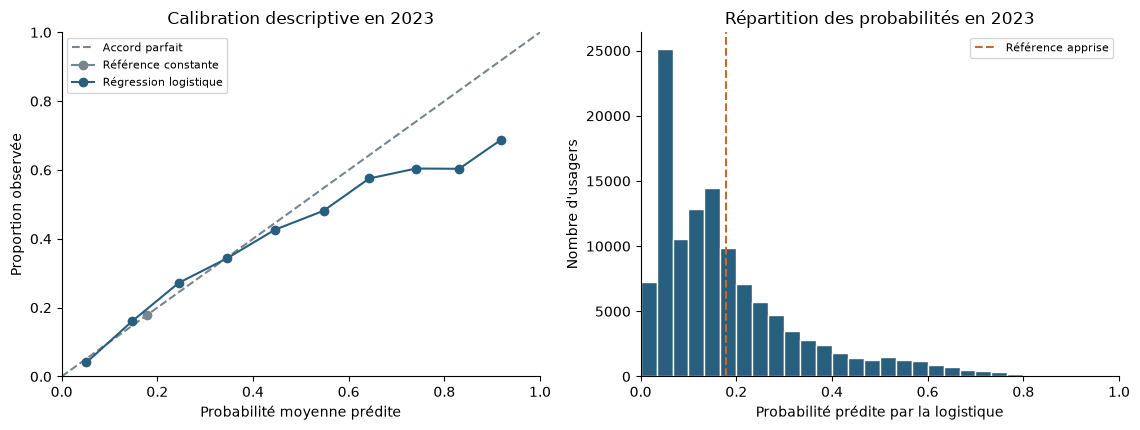

In [10]:
calibration_parts = []
for label, probabilities in [("Référence constante", reference_predictions),
                             ("Régression logistique", best_predictions)]:
    frame = pd.DataFrame({"probabilite": probabilities, "cible": y_validation})
    frame["intervalle"] = pd.cut(frame["probabilite"], bins=np.linspace(0, 1, 11), include_lowest=True)
    grouped = frame.groupby("intervalle", observed=True).agg(
        usagers=("cible", "size"), cas_positifs=("cible", "sum"),
        probabilite_moyenne=("probabilite", "mean"), proportion_observee=("cible", "mean"),
    ).reset_index()
    grouped["intervalle"] = grouped["intervalle"].astype(str)
    grouped.insert(0, "modele", label)
    calibration_parts.append(grouped)
calibration_table = pd.concat(calibration_parts, ignore_index=True)
export_table(calibration_table, "06_calibration_validation.csv")
display(calibration_table)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
axes[0].plot([0, 1], [0, 1], linestyle="--", color=GREY, label="Accord parfait")
for label, color in [("Référence constante", GREY), ("Régression logistique", BLUE)]:
    points = calibration_table.loc[calibration_table["modele"].eq(label)]
    axes[0].plot(points["probabilite_moyenne"], points["proportion_observee"], marker="o", color=color, label=label)
axes[0].set(xlabel="Probabilité moyenne prédite", ylabel="Proportion observée",
            title="Calibration descriptive en 2023", xlim=(0, 1), ylim=(0, 1))
axes[0].legend(fontsize=8)
axes[1].hist(best_predictions, bins=np.linspace(0, 1, 31), color=BLUE, edgecolor="white")
axes[1].axvline(reference_probability, linestyle="--", color=ORANGE, label="Référence apprise")
axes[1].set(xlabel="Probabilité prédite par la logistique", ylabel="Nombre d'usagers",
            title="Répartition des probabilités en 2023", xlim=(0, 1))
axes[1].legend(fontsize=8)
fig.tight_layout()
export_figure(fig, "06_01_calibration_validation.png")
plt.show()


La courbe précision-rappel répond à une autre question : lorsqu'on abaisse progressivement
le seuil, combien de cas positifs retrouve-t-on et quelle part des alertes est correcte ?
La ligne horizontale représente ici la proportion positive de 2023, une référence descriptive
pour la précision. Elle ne remplace pas la probabilité constante apprise sur 2019-2022.


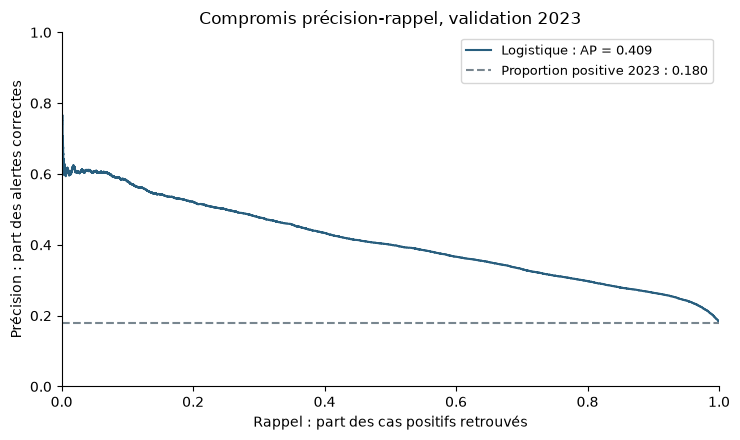

In [11]:
precision, recall, thresholds = precision_recall_curve(y_validation, best_predictions)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.step(recall, precision, where="post", color=BLUE,
        label=f"Logistique : AP = {best_metrics['average_precision']:.3f}")
ax.axhline(y_validation.mean(), color=GREY, linestyle="--",
           label=f"Proportion positive 2023 : {y_validation.mean():.3f}")
ax.set(xlabel="Rappel : part des cas positifs retrouvés", ylabel="Précision : part des alertes correctes",
       title="Compromis précision-rappel, validation 2023", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=9)
fig.tight_layout()
export_figure(fig, "06_02_precision_rappel_validation.png")
plt.show()


## 6. Montrer les erreurs avec un seuil explicite

Le seuil 0,5 est fixé avant l'entraînement pour illustrer une décision binaire. Au-dessus ou
à égalité, nous prédisons la classe 1. Il ne correspond pas à un coût métier justifié et n'est
pas présenté comme un seuil optimal. Les probabilités restent le résultat principal.

Une fausse alerte est un usager de classe 0 prédit en classe 1. Un cas manqué est un usager
de classe 1 prédit en classe 0. Précision et rappel répondent à des questions différentes :
la précision part des alertes, le rappel part des véritables décès ou hospitalisations.


In [12]:
threshold_rows = []
for label, probabilities in [("Référence constante", reference_predictions),
                             ("Régression logistique", best_predictions)]:
    predicted = (probabilities >= ILLUSTRATIVE_THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_validation, predicted, labels=[0, 1]).ravel()
    alerts = int(predicted.sum())
    threshold_rows.append({
        "modele": label, "seuil": ILLUSTRATIVE_THRESHOLD,
        "vrais_negatifs": int(tn), "fausses_alertes": int(fp),
        "cas_manques": int(fn), "vrais_positifs": int(tp), "alertes": alerts,
        "precision": float(tp / alerts) if alerts else np.nan,
        "rappel": float(tp / (tp + fn)), "accuracy": float((tp + tn) / len(y_validation)),
    })
threshold_table = pd.DataFrame(threshold_rows)
export_table(threshold_table, "06_erreurs_seuil_050.csv")
display(threshold_table)
print("La précision est indéfinie lorsque le modèle ne déclenche aucune alerte : elle reste manquante.")


,modele,seuil,vrais_negatifs,fausses_alertes,cas_manques,vrais_positifs,alertes,precision,rappel,accuracy
0,Référence constante,0.5,96883,0,21218,0,0,NaN,0.000000,0.820340
1,Régression logistique,0.5,93460,3423,17367,3851,7274,0.52942,0.181497,0.823964


La précision est indéfinie lorsque le modèle ne déclenche aucune alerte : elle reste manquante.


Au seuil de 0,5, la référence ne déclenche aucune alerte et atteint pourtant **82,03 %**
de bonnes réponses. La logistique atteint **82,40 %**, mais cette proximité masque un autre
comportement : elle déclenche **7 272 alertes**, dont **3 850 correctes** et **3 422 fausses alertes**.
Elle manque **17 368 cas positifs**, soit un rappel de **18,14 %**, pour une précision de **52,94 %**.

La logistique apporte donc de l'information dans ses probabilités, tout en détectant une
minorité des cas positifs à ce seuil. Le seuil de 0,5 ne peut pas être défendu comme une règle
opérationnelle sur la seule base de ces chiffres. Nous ne le réoptimisons pas ici.

## 7. Vérifier les sous-populations et les informations absentes

Un score global peut masquer des différences entre conducteurs, passagers et piétons.
Nous publions donc les effectifs, la fréquence observée, la probabilité moyenne et les
scores probabilistes de la logistique par catégorie d'usager. Ces diagnostics ne constituent
ni un contrôle d'équité complet ni une preuve causale.

Nous comparons aussi les mêmes prédictions sur les seuls usagers de 2023 dont l'âge et le sexe
sont renseignés. La référence reste celle apprise initialement. Aucun modèle n'est réentraîné
et aucune nouvelle stratégie n'est choisie à partir de ce contrôle. Cette restriction change
la population évaluée ; elle ne corrige pas un biais de données manquantes.


,dimension,groupe,usagers,cas_positifs,proportion_observee,probabilite_moyenne,log_loss,brier,average_precision,roc_auc,log_loss_reference,brier_reference
0,catégorie,Conducteur,87938,14768,0.167937,0.169243,0.372274,0.116484,0.435587,0.791911,0.452942,0.139833
1,catégorie,Passager,21171,3570,0.168627,0.169007,0.418977,0.130975,0.310211,0.702215,0.453999,0.140277
2,catégorie,Piéton,8992,2880,0.320285,0.329113,0.636935,0.221830,0.404031,0.607363,0.686160,0.237983
3,complétude,Âge et sexe renseignés,115742,21218,0.183322,0.185016,0.408910,0.129690,0.408521,0.764198,0.476494,0.149744
4,complétude,Âge ou sexe non renseigné,2359,0,0.000000,0.002642,0.002713,0.000133,NaN,NaN,0.195861,0.031639


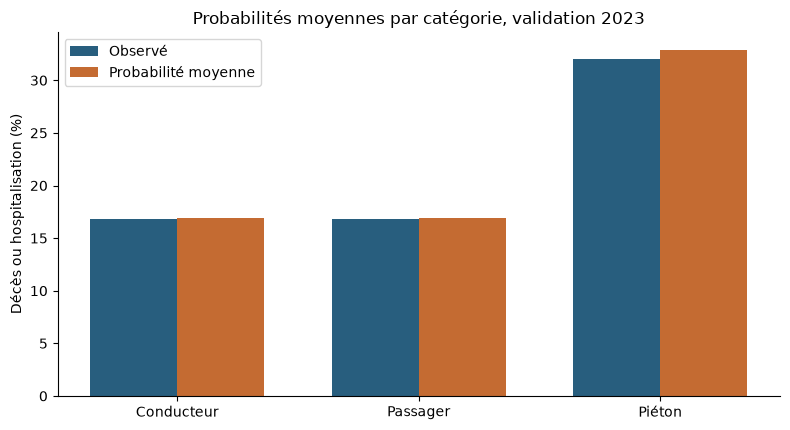

In [13]:
category_labels = {"1": "Conducteur", "2": "Passager", "3": "Piéton"}
segment_rows = []
segment_specs = [("catégorie", label, validation["catu"].eq(value).to_numpy(dtype=bool))
                 for value, label in category_labels.items()]
for label, mask in [
    ("Âge et sexe renseignés", validation[["age_approx", "sexe"]].notna().all(axis=1).to_numpy(dtype=bool)),
    ("Âge ou sexe non renseigné", validation[["age_approx", "sexe"]].isna().any(axis=1).to_numpy(dtype=bool)),
]:
    segment_specs.append(("complétude", label, mask))
for dimension, label, mask in segment_specs:
    if not mask.any():
        continue
    y_segment, p_segment = y_validation[mask], best_predictions[mask]
    segment_rows.append({
        "dimension": dimension, "groupe": label, "usagers": int(mask.sum()),
        "cas_positifs": int(y_segment.sum()), "proportion_observee": float(y_segment.mean()),
        "probabilite_moyenne": float(p_segment.mean()), **probability_metrics(y_segment, p_segment),
        "log_loss_reference": probability_metrics(y_segment, reference_predictions[mask])["log_loss"],
        "brier_reference": probability_metrics(y_segment, reference_predictions[mask])["brier"],
    })
segments = pd.DataFrame(segment_rows)
export_table(segments, "06_diagnostics_sous_populations.csv")
display(segments)

category_points = segments.loc[segments["dimension"].eq("catégorie")]
x = np.arange(len(category_points))
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.bar(x - 0.18, 100 * category_points["proportion_observee"], width=0.36, color=BLUE, label="Observé")
ax.bar(x + 0.18, 100 * category_points["probabilite_moyenne"], width=0.36, color=ORANGE, label="Probabilité moyenne")
ax.set_xticks(x, category_points["groupe"])
ax.set(ylabel="Décès ou hospitalisation (%)", title="Probabilités moyennes par catégorie, validation 2023")
ax.legend()
fig.tight_layout()
export_figure(fig, "06_03_diagnostics_categories_validation.png")
plt.show()


La ROC-AUC vaut **0,792 chez les conducteurs**, **0,702 chez les passagers** et **0,607 chez les
piétons**. Le modèle distingue donc moins bien les issues individuelles parmi les piétons,
même si leur probabilité moyenne prédite (32,91 %) reste assez proche de la proportion observée
(32,03 %). Un accord moyen n'implique pas un bon classement à l'intérieur d'un groupe.

Les **2 359 usagers dont l'âge ou le sexe manque ont tous une cible 0 dans la validation**.
Ce constat décrit le fichier ; il ne permet pas d'affirmer pourquoi ces informations manquent
ni de conclure que ces personnes seraient protégées. La faible probabilité prédite dans ce
groupe peut refléter les pratiques de collecte. L'AP et la ROC-AUC y restent manquantes dans
notre tableau, car une seule classe est présente.

Sur les **115 742 usagers dont l'âge et le sexe sont renseignés**, la log-loss de la logistique
reste inférieure à la référence (**0,4089 contre 0,4765**). Le gain ne disparaît donc pas lorsque
ce groupe particulier est écarté, sans que cela suffise à corriger les biais de collecte.

La calibration montre aussi des écarts : dans la tranche de probabilités 0,7-0,8, la moyenne
prédite est de 74,05 % pour une proportion observée de 60,49 %. Les tranches les plus élevées
comportent moins d'usagers, notamment seulement 16 au-dessus de 0,9. Nous ne concluons pas à
une calibration parfaite et n'ajustons pas de correction supplémentaire dans cette comparaison.

### Lire quatre contrastes dans le modèle combiné

Nous retrouvons les comparaisons du notebook 05, mais leur mesure change. Pour deux modalités
A et R d'une même variable, la différence de coefficients donne un rapport de cotes
`exp(coefficient_A - coefficient_R)`, les autres variables du modèle étant maintenues identiques.
Les cotes valent `p / (1 - p)` : ce rapport n'est pas le rapport des probabilités du notebook 05.

Les quatre contrastes sont fixés avant cette lecture. Ils décrivent la régression pénalisée,
sans intervalle d'incertitude et sans interprétation causale. Le modèle ne garantit pas que
chaque combinaison de caractéristiques existe réellement dans les données.


In [14]:
coefficients = dict(zip(encoder.get_feature_names_out(), best_model.named_steps["regression"].coef_[0]))
contrast_specs = [
    ("75 ans ou plus / 35-44 ans", "tranche_age", "75 ans ou plus", "35-44 ans"),
    ("Piéton / conducteur", "catu", "3", "1"),
    ("Nuit sans éclairage / plein jour", "lum", "3", "1"),
    ("Hors / en agglomération", "agg", "1", "2"),
]
model_contrasts = []
for label, variable, modality, reference in contrast_specs:
    difference = float(coefficients[f"{variable}_{modality}"] - coefficients[f"{variable}_{reference}"])
    model_contrasts.append({"comparaison": label, "difference_log_cotes": difference,
                            "rapport_de_cotes_penalise": float(np.exp(difference))})
model_contrasts = pd.DataFrame(model_contrasts)
export_table(model_contrasts, "06_contrastes_logistique.csv")
display(model_contrasts)


,comparaison,difference_log_cotes,rapport_de_cotes_penalise
0,75 ans ou plus / 35-44 ans,1.369273,3.932489
1,Piéton / conducteur,1.608413,4.994880
2,Nuit sans éclairage / plein jour,0.219138,1.245003
3,Hors / en agglomération,1.202636,3.328880


Dans cette régression, les rapports de cotes valent environ **3,93 pour l'âge**, **5,00 pour
piéton contre conducteur**, **1,24 pour nuit sans éclairage contre jour** et **3,33 pour hors
contre en agglomération**. Ils décrivent les contrastes du modèle combiné, sous ses hypothèses
et sa pénalisation. On ne peut pas attribuer leur différence avec les rapports du notebook 05 au seul ajustement :
les deux tableaux utilisent aussi des mesures différentes, cotes et proportions.

## 8. Arrêter une configuration pour le test final

Nous enregistrons le paramètre sélectionné, la référence, les règles de représentation,
les empreintes des entrées et les scores de validation. L'évaluation suivante réutilisera
la même période d'apprentissage et ces choix, sans ajouter 2023 à l'entraînement.
Cela permettra d'évaluer sur 2024 le même protocole que celui comparé ici.

La configuration contient des règles et des nombres, pas un fichier de modèle sérialisé.
Le modèle pourra être reconstruit depuis les mêmes données et le même environnement.
Les nouveaux codes éventuels de 2024 seront signalés sans réajuster l'encodeur sur le test.

Les scores de ce notebook sont des descriptions de 2023 après sélection de `C`. Nous ne
calculons ni intervalle indépendant par usager ni test de significativité ignorant les
liens entre les personnes d'un même accident. La préparation et la séparation temporelle
ne corrigent pas les erreurs de collecte, la sous-déclaration ou la sélection des cas connus.


In [15]:
configuration = {
    **protocol, "date_selection_utc": datetime.now(timezone.utc).isoformat(),
    "modele_retenu": selected_name, "C_retenu_logistique": best_c,
    "probabilite_reference": reference_probability,
    "scores_validation_reference": reference_metrics,
    "scores_validation_logistique": best_metrics,
    "gain_relatif_log_loss_pct": gain_log_loss_pct, "gain_relatif_brier_pct": gain_brier_pct,
    "usagers_apprentissage": len(train), "usagers_validation": len(validation),
    "colonnes_apres_encodage": int(len(encoder.get_feature_names_out())),
    "aucun_score_test_calcule": True,
}
metadata = {
    "notebook": "06_logistic_regression.ipynb", "environnement": environment,
    "sha256_donnees": input_sha256, "sha256_schema": schema_sha256,
    "sha256_module": module_sha256, "annees_utilisees": [*TRAIN_YEARS, VALIDATION_YEAR],
    "tables": tables_written, "figures": figures_written,
    "protocole": "06_protocole_modelisation.json", "configuration": "06_configuration_retenue.json",
    "dependance_intra_accident": "aucun intervalle indépendant par usager ; scores descriptifs sur 2023",
}
assert file_sha256(DATA_PATH) == input_sha256
assert list(encoder.feature_names_in_) == MODEL_FEATURES
if EXPORT_RESULTS:
    assert len(tables_written) == 9 and len(figures_written) == 3
    for filename, content in [
        ("06_configuration_retenue.json", configuration), ("06_metadonnees_modelisation.json", metadata),
    ]:
        (TABLE_DIR / filename).write_text(json.dumps(content, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(pd.Series({
    "modèle_retenu": selected_name, "C_logistique": best_c,
    "colonnes_après_encodage": configuration["colonnes_apres_encodage"],
    "tableaux_CSV_exportés": len(tables_written), "graphiques_exportés": len(figures_written),
    "année_du_prochain_test": 2024,
}, name="bilan"))


modèle_retenu              regression_logistique
C_logistique                                 1.0
colonnes_après_encodage                      117
tableaux_CSV_exportés                          9
graphiques_exportés                            3
année_du_prochain_test                      2024
Name: bilan, dtype: object

## Conclusion

**Sur 2023, le modèle combinant les onze caractéristiques fait mieux que la référence constante
pour la log-loss et le score de Brier.** La configuration retenue est une régression logistique
L2 avec C = 1 et un apprentissage sur 2019-2022. Les améliorations relatives sont respectivement
de 14,88 % et 13,76 %.

Cette réponse positive reste limitée à notre question de validation. La calibration est imparfaite,
les performances diffèrent selon les catégories et le seuil illustratif de 0,5 ne détecte que
18,14 % des cas positifs. La représentation des données manquantes capte une particularité du
fichier qui doit être discutée. **Aucun résultat de test sur 2024 n'est encore disponible.**

Le travail réalisé comprend une séparation temporelle contrôlée, une sélection explicite de
variables, un prétraitement ajusté sur l'apprentissage et une comparaison avec une référence.
Les valeurs manquantes et les nouvelles modalités sont suivies, plutôt que cachées par la lecture du CSV.

Une différence de score ne démontre pas une utilité opérationnelle. La cible reste sensible
à l'enregistrement de l'hospitalisation et les relations apprises restent non causales.
Le modèle est additif sur les log-cotes, sans interaction explicite entre catégorie d'usager
et véhicule, et l'âge est regroupé : ce sont des limites de cette première représentation.

La prochaine étape sera l'évaluation sur 2024, avec la configuration conservée. Elle permettra
d'examiner si les performances observées en validation se maintiennent sur une année ultérieure.
Si elles se dégradent, nous le rapporterons sans réoptimiser le modèle sur ce test.

### Références techniques

- [scikit-learn : OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [scikit-learn : LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [scikit-learn : évaluation des modèles](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [scikit-learn : calibration des probabilités](https://scikit-learn.org/stable/modules/calibration.html)
- [scikit-learn : éviter les fuites entre apprentissage et test](https://scikit-learn.org/stable/common_pitfalls.html)

Les règles de population et de cible proviennent du schéma et des notebooks 01 à 05 du projet.
